INSTALLING DEPENDENCIES
✓ Packages installed
⚠ torch_xla not available, using GPU/CPU
Using device: cuda
TRAINING: EfficientNet-B5
Device: GPU

Training samples: 2929
Validation samples: 733
Class weights: [0.40576178 1.9794594  0.73313314 3.7948186  2.4827118 ]
✓ Total samples: 21935
Downloading: "https://download.pytorch.org/models/efficientnet_b5_lukemelas-1a07897c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b5_lukemelas-1a07897c.pth


100%|██████████| 117M/117M [00:00<00:00, 193MB/s] 



Starting training...
Batch size: 16
Image size: 256
Learning rate: 0.0002


Epoch 1 [Valid]: 100%|██████████| 46/46 [01:18<00:00,  1.72s/it]



Epoch 1/30 (891.0s)
  Train - Loss: 1.3607, QWK: 0.5902, Acc: 0.3582, F1: 0.2597
  Valid - Loss: 0.6448, QWK: 0.6833, Acc: 0.2306, F1: 0.1789
  ✓ Best model saved! QWK: 0.6833


Epoch 2 [Valid]: 100%|██████████| 46/46 [01:14<00:00,  1.61s/it]


... (53 outputs left out)

Epoch 29 [Valid]: 100%|██████████| 46/46 [01:15<00:00,  1.65s/it]



Epoch 29/30 (848.5s)
  Train - Loss: 0.0907, QWK: 0.9025, Acc: 0.7740, F1: 0.7574
  Valid - Loss: 0.1348, QWK: 0.9524, Acc: 0.9086, F1: 0.9118


Epoch 30 [Valid]: 100%|██████████| 46/46 [01:16<00:00,  1.65s/it]



Epoch 30/30 (846.9s)
  Train - Loss: 0.0951, QWK: 0.9066, Acc: 0.7751, F1: 0.7600
  Valid - Loss: 0.1329, QWK: 0.9520, Acc: 0.9072, F1: 0.9106


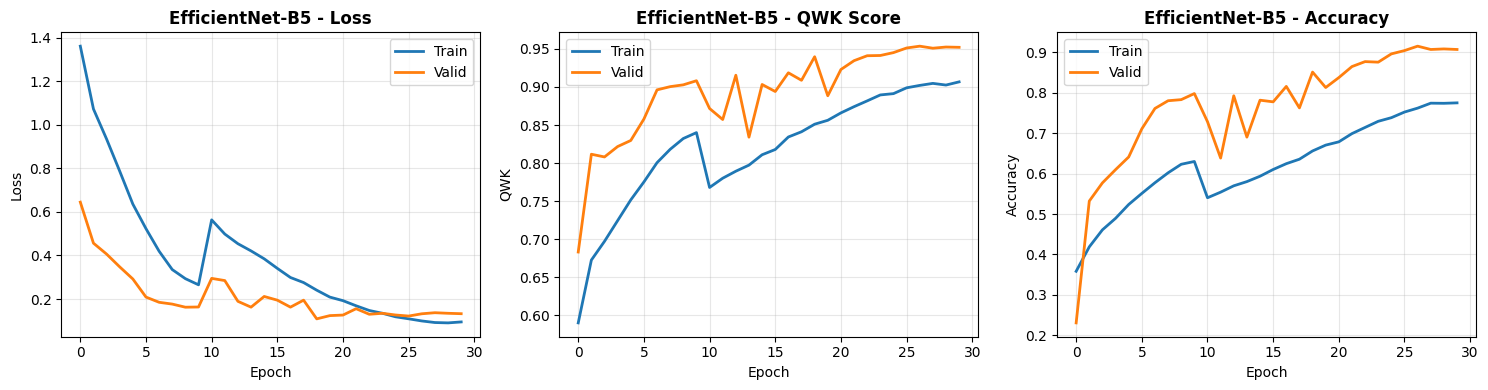


TRAINING COMPLETE!
Model: EfficientNet-B5
Best QWK: 0.9535
Model saved to: /kaggle/working/models/EfficientNet-B5_best.pth


In [1]:
# ============================================
# MODEL 1: EfficientNet-B5 TRAINING
# Diabetic Retinopathy Detection
# ============================================

import os
import sys
import subprocess

print("="*80)
print("INSTALLING DEPENDENCIES")
print("="*80)

try:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 
                          'opencv-python-headless', 'scikit-learn', 
                          'matplotlib', 'seaborn', 'tqdm', 'pillow'])
    print("✓ Packages installed")
except Exception as e:
    print(f"⚠ Note: {e}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from tqdm import tqdm
import warnings
import time
from collections import defaultdict
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts

# Check device
TPU_AVAILABLE = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    import torch_xla.distributed.parallel_loader as pl
    import torch_xla.distributed.xla_multiprocessing as xmp
    
    try:
        test_device = xm.xla_device()
        print(f"✓ TPU detected: {test_device}")
        TPU_AVAILABLE = True
        device = test_device
    except:
        print("⚠ TPU not available, using GPU/CPU")
except ImportError:
    print("⚠ torch_xla not available, using GPU/CPU")

print(f"Using device: {device}")

import torchvision
import torchvision.transforms as transforms
from torchvision.models import efficientnet_b5

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# ============================================
# CONFIGURATION
# ============================================
class Config:
    APTOS_TRAIN_CSV = '/kaggle/input/competitions/aptos2019-blindness-detection/train.csv'
    APTOS_TRAIN_IMAGES = '/kaggle/input/competitions/aptos2019-blindness-detection/train_images'
    AUGMENTED_TRAIN = '/kaggle/input/datasets/ascanipek/eyepacs-aptos-messidor-diabetic-retinopathy/augmented_resized_V2/train'
    DR_UNIFIED_TRAIN = '/kaggle/input/datasets/ascanipek/eyepacs-aptos-messidor-diabetic-retinopathy/dr_unified_v2/dr_unified_v2/train'
    
    OUTPUT_DIR = '/kaggle/working'
    MODEL_NAME = 'EfficientNet-B5'
    
    NUM_EPOCHS = 30
    NUM_CLASSES = 5
    
    if TPU_AVAILABLE:
        IMAGE_SIZE = 512
        BATCH_SIZE = 64
        LEARNING_RATE = 1e-3
    else:
        IMAGE_SIZE = 256
        BATCH_SIZE = 16
        LEARNING_RATE = 2e-4
    
    WEIGHT_DECAY = 1e-5
    
    CLASS_NAMES = {
        0: 'No DR', 1: 'Mild', 2: 'Moderate',
        3: 'Severe', 4: 'Proliferative DR'
    }

os.makedirs(Config.OUTPUT_DIR + '/models', exist_ok=True)
os.makedirs(Config.OUTPUT_DIR + '/plots', exist_ok=True)

# ============================================
# MODEL: EfficientNet-B5
# ============================================
class EfficientNetB5Model(nn.Module):
    def __init__(self, num_classes=5, dropout_rate=0.5):
        super().__init__()
        self.backbone = efficientnet_b5(weights='IMAGENET1K_V1')
        in_features = self.backbone.classifier[1].in_features
        
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.6),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)

# ============================================
# LOSS FUNCTION
# ============================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        if alpha is not None:
            self.register_buffer('alpha', alpha)
        else:
            self.alpha = None
        self.gamma = gamma
    
    def forward(self, inputs, targets):
        if self.alpha is not None:
            ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        else:
            ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        return ((1 - pt) ** self.gamma * ce_loss).mean()

# ============================================
# METRICS
# ============================================
def qwk_score(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights='quadratic')

def compute_metrics(y_true, y_pred):
    return {
        'qwk': qwk_score(y_true, y_pred),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

# ============================================
# DATASET
# ============================================
class RetinopathyDataset(Dataset):
    def __init__(self, df, image_dir, transform=None):
        self.image_paths = []
        self.labels = []
        self.transform = transform
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        
        for _, row in df.iterrows():
            self.image_paths.append(os.path.join(image_dir, f"{row['id_code']}.png"))
            self.labels.append(row['diagnosis'])
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l = self.clahe.apply(l)
        lab = cv2.merge([l, a, b])
        img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        
        img = Image.fromarray(img)
        if self.transform:
            img = self.transform(img)
        
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

class CombinedDataset(Dataset):
    def __init__(self, aptos_df, aptos_dir, augmented_dirs, transform=None, max_samples=2000):
        self.transform = transform
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        self.samples = []
        
        for _, row in aptos_df.iterrows():
            self.samples.append({
                'path': os.path.join(aptos_dir, f"{row['id_code']}.png"),
                'label': row['diagnosis']
            })
        
        for aug_dir in augmented_dirs:
            if os.path.exists(aug_dir):
                for class_idx in range(5):
                    class_path = os.path.join(aug_dir, str(class_idx))
                    if os.path.exists(class_path):
                        images = [f for f in os.listdir(class_path) 
                                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
                        if len(images) > max_samples:
                            images = np.random.choice(images, max_samples, replace=False)
                        for img_name in images:
                            self.samples.append({
                                'path': os.path.join(class_path, img_name),
                                'label': class_idx
                            })
        
        print(f"✓ Total samples: {len(self.samples)}")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        img = cv2.imread(sample['path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l = self.clahe.apply(l)
        lab = cv2.merge([l, a, b])
        img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        
        img = Image.fromarray(img)
        if self.transform:
            img = self.transform(img)
        
        return img, torch.tensor(sample['label'], dtype=torch.long)

# ============================================
# TRANSFORMS
# ============================================
def get_train_transforms():
    return transforms.Compose([
        transforms.Resize((Config.IMAGE_SIZE, Config.IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=20),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

def get_valid_transforms():
    return transforms.Compose([
        transforms.Resize((Config.IMAGE_SIZE, Config.IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

# ============================================
# TRAINING FUNCTIONS
# ============================================
def train_epoch(model, loader, criterion, optimizer, device, epoch):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    
    pbar = tqdm(loader, desc=f'Epoch {epoch+1} [Train]')
    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        if TPU_AVAILABLE:
            xm.optimizer_step(optimizer)
        else:
            optimizer.step()
        
        total_loss += loss.item()
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        pbar.set_postfix({'loss': f'{loss.item():.3f}'})
    
    return total_loss / len(loader), compute_metrics(all_labels, all_preds)

def validate_epoch(model, loader, criterion, device, epoch):
    model.eval()
    total_loss = 0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=f'Epoch {epoch+1} [Valid]'):
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    return total_loss / len(loader), compute_metrics(all_labels, all_preds)

def plot_training_history(history, model_name):
    """Plot training history"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Loss
    axes[0].plot(history['train_loss'], label='Train', linewidth=2)
    axes[0].plot(history['valid_loss'], label='Valid', linewidth=2)
    axes[0].set_title(f'{model_name} - Loss', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # QWK
    axes[1].plot(history['train_qwk'], label='Train', linewidth=2)
    axes[1].plot(history['valid_qwk'], label='Valid', linewidth=2)
    axes[1].set_title(f'{model_name} - QWK Score', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('QWK')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Accuracy
    axes[2].plot(history['train_acc'], label='Train', linewidth=2)
    axes[2].plot(history['valid_acc'], label='Valid', linewidth=2)
    axes[2].set_title(f'{model_name} - Accuracy', fontweight='bold')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'{Config.OUTPUT_DIR}/plots/{model_name}_history.png', dpi=150, bbox_inches='tight')
    plt.show()

# ============================================
# MAIN TRAINING
# ============================================
def main():
    print("="*80)
    print(f"TRAINING: {Config.MODEL_NAME}")
    print(f"Device: {'TPU v3-8' if TPU_AVAILABLE else ('GPU' if torch.cuda.is_available() else 'CPU')}")
    print("="*80)
    
    # Load data
    train_df = pd.read_csv(Config.APTOS_TRAIN_CSV)
    class_weights = torch.tensor(
        compute_class_weight('balanced', classes=np.array([0,1,2,3,4]), y=train_df['diagnosis'].values),
        dtype=torch.float32
    )
    
    train_df, valid_df = train_test_split(
        train_df, test_size=0.2, stratify=train_df['diagnosis'], random_state=42
    )
    
    print(f"\nTraining samples: {len(train_df)}")
    print(f"Validation samples: {len(valid_df)}")
    print(f"Class weights: {class_weights.numpy()}")
    
    # Create datasets
    train_dataset = CombinedDataset(
        train_df, Config.APTOS_TRAIN_IMAGES,
        [Config.AUGMENTED_TRAIN, Config.DR_UNIFIED_TRAIN],
        transform=get_train_transforms(),
        max_samples=2000
    )
    
    valid_dataset = RetinopathyDataset(
        valid_df, Config.APTOS_TRAIN_IMAGES,
        transform=get_valid_transforms()
    )
    
    # Create loaders
    if TPU_AVAILABLE:
        train_sampler = torch.utils.data.distributed.DistributedSampler(
            train_dataset, num_replicas=xm.xrt_world_size(),
            rank=xm.get_ordinal(), shuffle=True
        )
        valid_sampler = torch.utils.data.distributed.DistributedSampler(
            valid_dataset, num_replicas=xm.xrt_world_size(),
            rank=xm.get_ordinal(), shuffle=False
        )
        
        train_loader = DataLoader(
            train_dataset, batch_size=Config.BATCH_SIZE,
            sampler=train_sampler, num_workers=4, drop_last=True
        )
        valid_loader = DataLoader(
            valid_dataset, batch_size=Config.BATCH_SIZE,
            sampler=valid_sampler, num_workers=4
        )
    else:
        train_loader = DataLoader(
            train_dataset, batch_size=Config.BATCH_SIZE,
            shuffle=True, num_workers=2, pin_memory=True
        )
        valid_loader = DataLoader(
            valid_dataset, batch_size=Config.BATCH_SIZE,
            shuffle=False, num_workers=2, pin_memory=True
        )
    
    # Create model
    model = EfficientNetB5Model(num_classes=Config.NUM_CLASSES).to(device)
    criterion = FocalLoss(alpha=class_weights.to(device), gamma=2.0)
    optimizer = optim.AdamW(model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)
    scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2)
    
    # Training loop
    best_qwk = 0
    patience = 7
    patience_counter = 0
    history = defaultdict(list)
    
    print(f"\nStarting training...")
    print(f"Batch size: {Config.BATCH_SIZE}")
    print(f"Image size: {Config.IMAGE_SIZE}")
    print(f"Learning rate: {Config.LEARNING_RATE}")
    
    for epoch in range(Config.NUM_EPOCHS):
        epoch_start = time.time()
        
        train_loss, train_metrics = train_epoch(model, train_loader, criterion, optimizer, device, epoch)
        valid_loss, valid_metrics = validate_epoch(model, valid_loader, criterion, device, epoch)
        
        scheduler.step()
        
        epoch_time = time.time() - epoch_start
        
        history['train_loss'].append(train_loss)
        history['train_qwk'].append(train_metrics['qwk'])
        history['train_acc'].append(train_metrics['accuracy'])
        history['valid_loss'].append(valid_loss)
        history['valid_qwk'].append(valid_metrics['qwk'])
        history['valid_acc'].append(valid_metrics['accuracy'])
        
        print(f"\nEpoch {epoch+1}/{Config.NUM_EPOCHS} ({epoch_time:.1f}s)")
        print(f"  Train - Loss: {train_loss:.4f}, QWK: {train_metrics['qwk']:.4f}, "
              f"Acc: {train_metrics['accuracy']:.4f}, F1: {train_metrics['f1']:.4f}")
        print(f"  Valid - Loss: {valid_loss:.4f}, QWK: {valid_metrics['qwk']:.4f}, "
              f"Acc: {valid_metrics['accuracy']:.4f}, F1: {valid_metrics['f1']:.4f}")
        
        # Per-class F1
        for i in range(5):
            history[f'valid_f1_class_{i}'].append(valid_metrics.get(f'f1_class_{i}', 0))
        
        if valid_metrics['qwk'] > best_qwk:
            best_qwk = valid_metrics['qwk']
            patience_counter = 0
            
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_qwk': best_qwk,
                'history': dict(history)
            }, f'{Config.OUTPUT_DIR}/models/{Config.MODEL_NAME}_best.pth')
            print(f"  ✓ Best model saved! QWK: {best_qwk:.4f}")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\n  Early stopping at epoch {epoch+1}")
                break
        
        if TPU_AVAILABLE:
            xm.mark_step()
    
    # Plot history
    plot_training_history(history, Config.MODEL_NAME)
    
    print(f"\n{'='*80}")
    print(f"TRAINING COMPLETE!")
    print(f"{'='*80}")
    print(f"Model: {Config.MODEL_NAME}")
    print(f"Best QWK: {best_qwk:.4f}")
    print(f"Model saved to: {Config.OUTPUT_DIR}/models/{Config.MODEL_NAME}_best.pth")
    
    return best_qwk, history

if __name__ == "__main__":
    if TPU_AVAILABLE:
        xmp.spawn(main, args=(), start_method='fork')
    else:
        main()